In [1]:
import numpy as np
import scipy as sp
import matplotlib.pyplot as plt
import CoolProp.CoolProp as CP
import thermo as thermo
import time as timer
import cProfile
import pstats
import yaml
import copy
import sys
from thermal import *

Fluid Property functions

In [ ]:
# Extracted to thermal/properties.py


Basic Fluid Flow Functions
Current assumptions:
Fully developed

In [ ]:
# Extracted to thermal/correlations.py


Thermal resistances

In [ ]:
# Extracted to thermal/correlations.py


Class definitions

In [ ]:
# Extracted to thermal/components.py


System modules section

In [ ]:
# Extracted to thermal/components.py


Simulation model

In [ ]:
# Extracted to thermal/simulation.py


Simulation inputs and running

In [5]:
# Define the YAML content
yaml_content = """
# Simulation Input Template

# General Simulation Parameters
time_steps: 180000  # Number of time steps for the simulation
end_time: 180000 # total simulation time
T_sur: 300 #Surroundings temperature
#T_batt_full: 2673 #battery zero charge temp
DT_batt_full: 50 #DT between max Tin temp and target battery full temp
T_tin_max_heat: 2723 #max Tin temp in heater
DT_batt: 500 #battery design temp range
init_batt_state: 1 #initial battery charge state
N_loops_step: 6 #simulation speed-up factor
heat_loss_bool: False #account for pipe heat loss
block_heat_loss_bool: False #account for block heat loss
simple_heater_bool: False #skip heater element temp calculation
bypass_bool: True #activate storage block bypass
powerstick_bypass_bool: False #activate storage block bypass
vary_flowrate_bool: False
print_outputs_bool: True
liner_bool: False #Tungsten liner or none

# Input Definitions
heat_inputs:
  - range: [0, 179999]
    value: 0e5  # Heat input in Watts
  #- range: [180000, 359999]
  #  value: 0e5  # Heat input in Watts
flow_rates:
  - range: [0, 179999]
    value: 17.5
emissivity_tables:
  - range: [0, 179999]
    value: 
      - [[0.05, 1.24], 0.9, 0.1, 0.1]  # Below bandgap
      - [[1.24, 40.0], 0.05, 0.1, 0.1]  # Above bandgap
  #- range: [180000, 359999]
  #  value:
  #    - [[0.05, 1.24], 0.9, 0.1, 0.1]  # Below bandgap
  #    - [[1.24, 40.0], 0.05, 0.1, 0.1]  # Above bandgap

#power_conversion_bypass_fractions:
#  - range: [0, 143999]
#    value: 0.3  # Fraction of flow rate bypassing the power conversion block


# Fluid Initial Conditions
N_stations: 8 #number of fluid locations tracked
initial_fluids:
  #temperature: 2173  # Temperature in Kelvin
  pressure: 1e6  # Pressure in Pascals
  flow_rate: 1  # Flow rate in kg/s

# Pump Parameters
pump:
  efficiency: 0.85  # Pump efficiency

# Heater Parameters
heater:
  heat_input: 1e6 # heat input [W]
  N_pipes: 10  # Number of pipes in the heater
  N_heat: 3 #number of heater planes
  H_panel: 0.5 #height of Tin-bearing heating panels
  H_heat: 0.5 #total height of heater elements in heater plane
  max_heater_temperature: 2773
  Pipe:
    length: 1.0  # Length of the pipe in meters
    OD: 0.0445  # Diameter of the pipe in meters
    wall_thickness: 0.0095  # Wall thickness of the pipe in meters
    roughness: 3e-5  # Roughness of the pipe in meters
    th_ins: 0.0 #insulation thickness

# Storage Module Parameters
storage:
  Volume: 34.6 # total storage volume
  N_pipes: 3  # Number of pipes in the storage module
  Pipe:
    length: 6  # Length of the pipe in meters
    OD: 0.07  # Diameter of the pipe in meters
    wall_thickness: 0.0095  # Wall thickness of the pipe in meters
    roughness: 3e-5  # Roughness of the pipe in meters
    th_ins: 0.0 #insulation thickness
  num_ax_segments: 6  # Number of axial segments in the storage module
  num_rad_segments: 10  # Number of radial segments in the storage module
  Block:
    #initial_temp: 2173  # Initial temperature distribution in the block (example values)
    inner_radius: 0.15  # Inner radius of the block in meters
    #outer_radius: 0.316  # Outer radius of the block in meters
    length: 6  # Length of the block in meters
    th_ins: 0.105 #insulation thickness
  Bypass:
    range: [0.001, 0.999] # Allowable bypass ratio range

# Power Conversion Block Parameters
power_conversion:
  axial_steps: 6  # Number of axial discretization steps
  N_cells: 1  # Number of powerstick/emitter assemblies
  height_pipe: 0.01  # Height of the rectangular pipe in meters
  width_emitter: 0.3175  # Width of the emitter in meters
  length: 3.048  # Length of the components in meters
  roughness_pipe: 3e-5  # Roughness of the pipe in meters
  width_powerstick: 0.13  # Width of the power stick in meters
  wall_thickness: 0.01  # Thickness of the graphite wall in meters
  cooling_temp: 313  # Cooling temperature to maintain the power stick in Kelvin
  #panel_efficiency: 0.5  # Panel conversion efficiency above bandgap
  f_bare: 0.05 # powerstick area fraction not covered by SNGC
  f_active: 0.85 # electrical generation area fraction of SNGC-covered area
  max_inlet_temp: 2173 # Maximum allowable temperature into PCB

# Pipe Parameters
pipes:
  - length: 2.0  # Length of the pipe in meters
    OD: 0.089  # Diameter of the pipe in meters
    wall_thickness: 0.005  # Wall thickness of the pipe in meters
    roughness: 3e-5  # Roughness of the pipe in meters
    th_ins: 0.001 # insulation thickness
  - length: 2.0  # Length of the pipe in meters
    OD: 0.089  # Diameter of the pipe in meters
    wall_thickness: 0.005  # Wall thickness of the pipe in meters
    roughness: 3e-5  # Roughness of the pipe in meters
    th_ins: 0.001 # insulation thickness
  - length: 2.0  # Length of the pipe in meters
    OD: 0.089  # Diameter of the pipe in meters
    wall_thickness: 0.005  # Wall thickness of the pipe in meters
    roughness: 3e-5  # Roughness of the pipe in meters
    th_ins: 0.001 # insulation thickness
  - length: 2.0  # Length of the pipe in meters
    OD: 0.089  # Diameter of the pipe in meters
    wall_thickness: 0.005  # Wall thickness of the pipe in meters
    roughness: 3e-5  # Roughness of the pipe in meters
    th_ins: 0.001 # insulation thickness
"""

# Write the YAML content to a file
with open('simulation_input_template.yaml', 'w') as file:
    file.write(yaml_content)

print("YAML file created successfully!")

YAML file created successfully!


In [3]:
# Load the input file
with open("simulation_input_template.yaml", "r") as file:
    input_data = yaml.safe_load(file)

# Helper function to generate time series from range definitions
def generate_time_series(range_definitions, time_steps):
    series = np.zeros(time_steps)
    for item in range_definitions:
        start, end = item['range']
        series[start:end+1] = item['value']
    return series

# Helper function to generate time series for emissivity table
def generate_emissivity_table_series(range_definitions, time_steps):
    series = [[] for _ in range(time_steps)]
    for item in range_definitions:
        start, end = item['range']
        for i in range(start, end+1):
            series[i] = [(tuple(pair[0]), float(pair[1]), float(pair[2]), float(pair[3])) for pair in item['value']]  # Ensure each entry is a list of tuples
    return series

# Helper function to generate uniform 2D temperature distribution
def generate_2d_temp_distribution(initial_temp, num_ax_segments, num_rad_segments):
    return np.full((num_ax_segments, num_rad_segments), initial_temp)
    
# Extract the parameters from the input file
time_steps = input_data["time_steps"]
end_time = input_data["end_time"]
heat_loss_bool = input_data["heat_loss_bool"]
block_heat_loss_bool = input_data["block_heat_loss_bool"]
simple_heater_bool = input_data["simple_heater_bool"]
bypass_bool = input_data["bypass_bool"]
powerstick_bypass_bool = input_data["powerstick_bypass_bool"]
vary_flowrate_bool = input_data["vary_flowrate_bool"]
N_loops_step = input_data["N_loops_step"]
print_outputs_bool = input_data["print_outputs_bool"]
liner_bool = input_data["liner_bool"]
T_sur = input_data["T_sur"]
#T_batt_empty = input_data["T_batt_empty"]
DT_batt_full = input_data["DT_batt_full"]
T_tin_max_heat = input_data["T_tin_max_heat"]
DT_batt = input_data["DT_batt"]
init_batt_state = input_data["init_batt_state"]
T_batt_empty = T_tin_max_heat - DT_batt_full - DT_batt
T_init = T_batt_empty + init_batt_state * DT_batt

#generate input time series
heat_inputs = generate_time_series(input_data["heat_inputs"], time_steps)
emissivity_tables = generate_emissivity_table_series(input_data["emissivity_tables"], time_steps)
flow_rates = generate_time_series(input_data["flow_rates"], time_steps)
#power_bypass = generate_time_series(input_data["power_conversion_bypass_fractions"], time_steps)

initial_conditions = input_data["initial_fluids"]
N_stations = input_data["N_stations"]
initial_fluids = [Fluid(temperature=T_init,
                        pressure=float(initial_conditions["pressure"]),
                        flow_rate=1) 
                  for _ in range(N_stations)]
V_tin_heater = input_data["heater"]["N_pipes"] * Pipe(**input_data["heater"]["Pipe"]).volume
# Create the components
pump = Pump(pump_efficiency=input_data["pump"]["efficiency"])
heater = HeatingModule(heat_input=input_data["heater"]["heat_input"], N_pipes=input_data["heater"]["N_pipes"], N_heat=input_data["heater"]["N_heat"],
                       H_panel=input_data["heater"]["H_panel"], H_heat=input_data["heater"]["H_heat"],
                       Pipe=Pipe(**input_data["heater"]["Pipe"]), simple_heat=simple_heater_bool, max_temperature=input_data["heater"]["max_heater_temperature"])
pipe_template = Pipe(**input_data["storage"]["Pipe"])

# Generate initial temperature distribution as a 2D array
num_ax_segments = input_data["storage"]["num_ax_segments"]
num_rad_segments = input_data["storage"]["num_rad_segments"]
#initial_temp = input_data["storage"]["Block"]["initial_temp"]
initial_temp_distribution = generate_2d_temp_distribution(T_init, num_ax_segments, num_rad_segments)

block_params = {k: v for k, v in input_data["storage"]["Block"].items() if k != "initial_temp"}

storage_bypass_range = input_data["storage"]["Bypass"]["range"]
V_storage = input_data["storage"]["Volume"]
N_blocks = input_data["storage"]["N_pipes"]
inner_radius = input_data["storage"]["Block"]["inner_radius"]
length = input_data["storage"]["Block"]["length"]
outer_radius = np.sqrt(V_storage / (N_blocks * length * np.pi) + inner_radius**2)
print("OD:", outer_radius * 2)
block_params["outer_radius"] = outer_radius
V_tin_storage = input_data["storage"]["N_pipes"] * pipe_template.volume
storage = StorageModule(Block=GraphiteBlock(initial_temp_distribution, **block_params),  
                        N_pipes=input_data["storage"]["N_pipes"], 
                        Pipe=pipe_template, 
                        num_ax_segments=input_data["storage"]["num_ax_segments"], 
                        num_rad_segments=input_data["storage"]["num_rad_segments"],
                        bypass_range=storage_bypass_range)

V_tin_power_conversion = 4 * input_data["power_conversion"]["N_cells"] * input_data["power_conversion"]["height_pipe"] * input_data["power_conversion"]["width_emitter"] * input_data["power_conversion"]["length"] 
power_conversion = PowerConversionBlock(
    axial_steps=int(input_data["power_conversion"]["axial_steps"]),
    N_cells=int(input_data["power_conversion"]["N_cells"]),
    height_pipe=float(input_data["power_conversion"]["height_pipe"]),
    width_emitter=float(input_data["power_conversion"]["width_emitter"]),
    length=float(input_data["power_conversion"]["length"]),
    roughness_pipe=float(input_data["power_conversion"]["roughness_pipe"]),
    width_powerstick=float(input_data["power_conversion"]["width_powerstick"]),
    wall_thickness=float(input_data["power_conversion"]["wall_thickness"]),
    cooling_temp=float(input_data["power_conversion"]["cooling_temp"]),
    T_tin_max_PCB=input_data["power_conversion"]["max_inlet_temp"],
    f_bare=input_data["power_conversion"]["f_bare"],
    f_active=input_data["power_conversion"]["f_active"],
    liner_bool=input_data["liner_bool"],
    emissivity_table=emissivity_tables[0]
    
)
pipes = [Pipe(**pipe) for pipe in input_data["pipes"]]
V_tin_pipes = sum(pipe.volume for pipe in pipes)
def disable_active_profiler():
    """
    Disable any currently active profiler.
    """
    try:
        sys.setprofile(None)
        print("Any active profiler has been disabled.")
    except Exception as e:
        print(f"Failed to disable profiler: {e}")

#def run_simulation_with_profiling():
# Measure the total execution time of the simulation
timer_start = timer.time()
# Disable any active profilers
#disable_active_profiler()
# Profile the simulation to identify the functions that take the most time
#profiler = cProfile.Profile()
#profiler.enable()

# Create the system simulation
simulation = SystemSimulation(pump, heater, storage, power_conversion, pipes, heat_loss_bool, block_heat_loss_bool, bypass_bool, powerstick_bypass_bool, vary_flowrate_bool, print_outputs_bool, liner_bool, N_loops_step, T_tin_max_heat)
V_tin_tot = V_tin_heater + V_tin_storage + V_tin_power_conversion + V_tin_pipes
mass_tin_tot = V_tin_tot * Sn_rho(initial_fluids[0].temperature)

print("Total Tin Volume: ", V_tin_tot)
print("Total storage block volume: ", V_storage)
# Run the simulation
try:
    results = simulation.run_simulation(initial_fluids, end_time, heat_inputs, flow_rates, emissivity_tables, T_sur, T_batt_empty, DT_batt, init_batt_state=init_batt_state)
except:
    #profiler.disable()
    print("error in sim")
    results = simulation.run_simulation(initial_fluids, end_time, heat_inputs, flow_rates, emissivity_tables, T_sur, T_batt_empty, DT_batt, init_batt_state=init_batt_state)
# Disable the profiler
#profiler.disable()

# Calculate the total execution time
#timer_end = timer.time()
#execution_time = timer_end - timer_start

#print(f"Total execution time: {execution_time:.2f} seconds")

# Print the profiling results
#profiler_stats = pstats.Stats(profiler)
#profiler_stats.sort_stats(pstats.SortKey.TIME)
#profiler_stats.print_stats()


OD: 1.592937333074354
Total Tin Volume:  0.11980078227354146
Total storage block volume:  34.6
2173 500
T_av_stor: 2673.0
Q_heat 0 0.0 262500.0 67363.1531212243 0.0
surf_loss: 0.0
False False True
Iteration:  1 Time:  0.011 Storage Bypass:  0.999 heat_input:  0 flow rate:  17.5 T_heat_in: 2673.0 T_heat_out: 2673.0 T_av_storage 2673.0 T_storage_inner_first 2673.0 Storage energy 13.94 T_PCB_in: 2673.0 T_PCB_out:  2498.3 Q_store:  0.0 Q_store_check:  0.0 Q_PCB:  917168.0 Q_tin: -917168.0 elec gen: 317889.0
T_av_stor: 2673.0
Q_heat 0 0.0 1179628.3800240268 67363.1531212243 0.0
surf_loss: 0.0
False False True
Iteration:  2 Time:  0.021 Storage Bypass:  0.999 heat_input:  0 flow rate:  17.5 T_heat_in: 2498.31 T_heat_out: 2498.31 T_av_storage 2673.0 T_storage_inner_first 2673.0 Storage energy 13.94 T_PCB_in: 2498.48 T_PCB_out:  2371.22 Q_store:  -917.0 Q_store_check:  -917.0 Q_PCB:  668122.0 Q_tin: -667165.0 elec gen: 255887.0
T_av_stor: 2672.9996481287158
Q_heat 0 900.4949320383572 1846795.0

-13.96448164377079 13.936111111111114 13.936111111111112
Max storage block temperature rise rate: 3.4865 K/min
  at location (radial, axial): (0, 0)
  at time: 45.37 hr
Max storage_inlet temperature rise rate: 10.4300 K/min at t = 45.23 hr
Max storage_outlet temperature rise rate: 4.7097 K/min at t = 45.23 hr


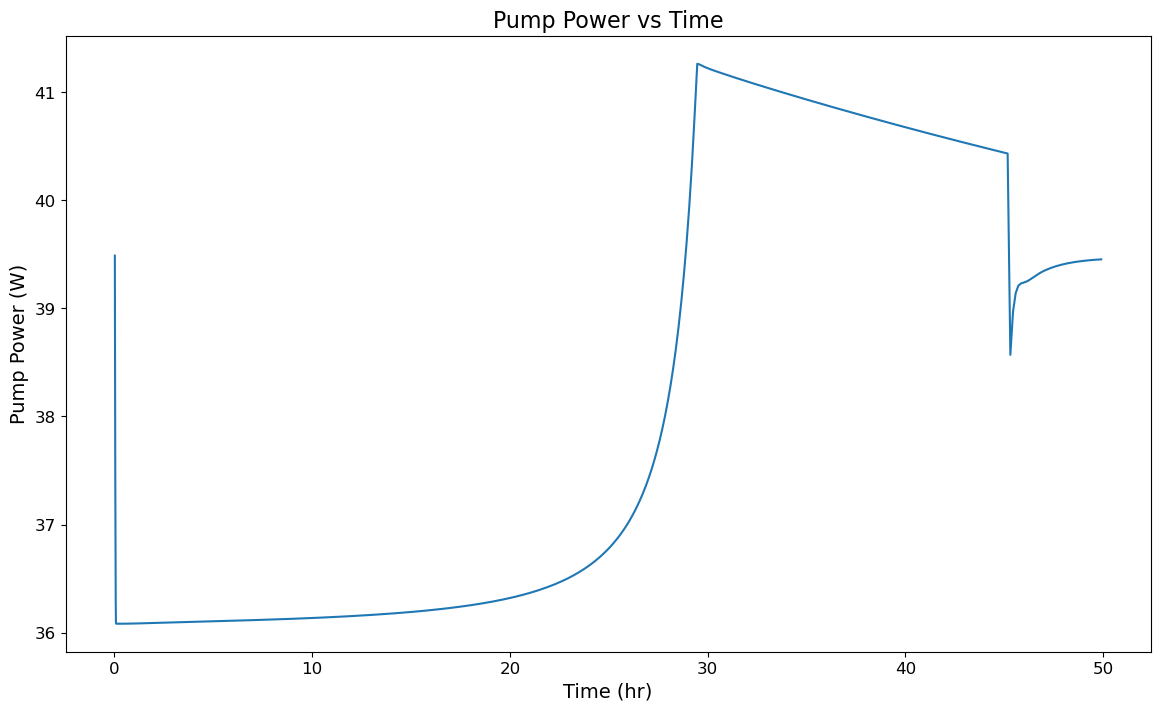

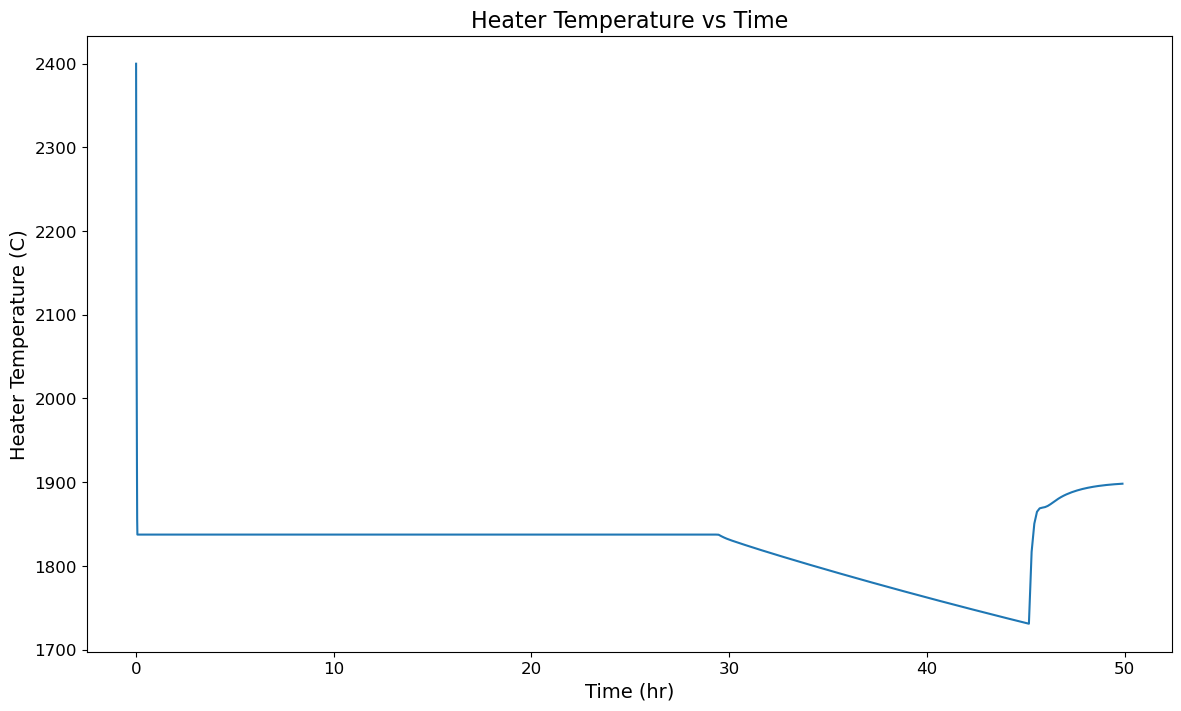

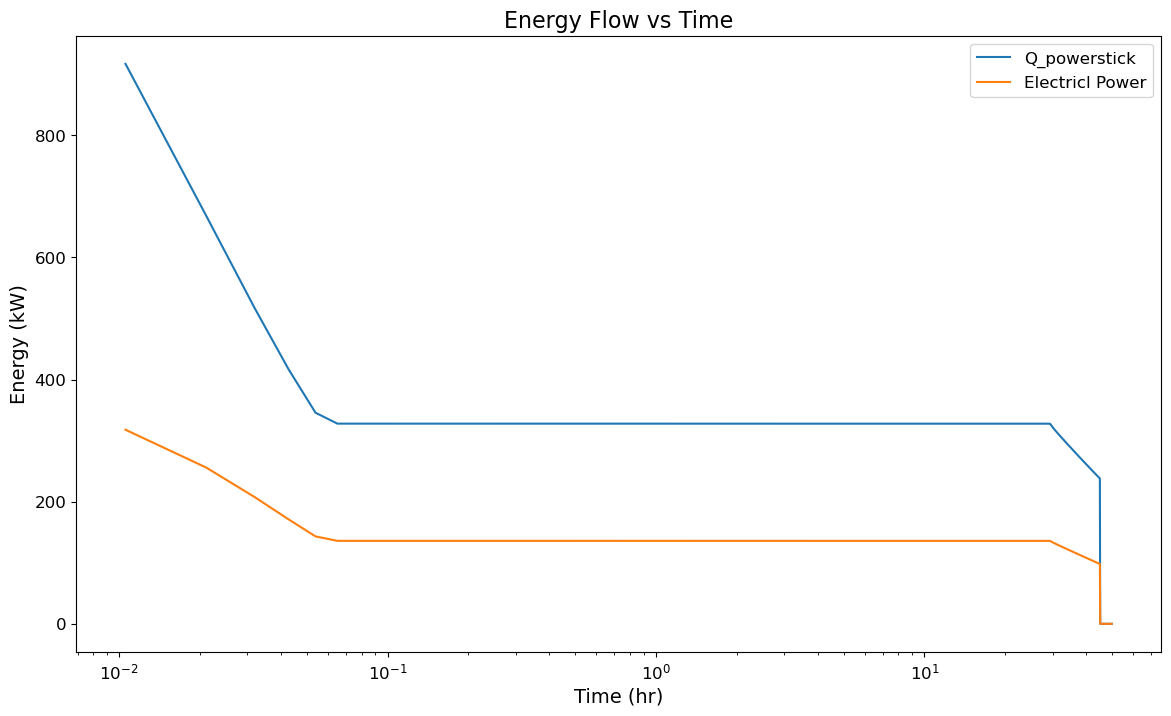

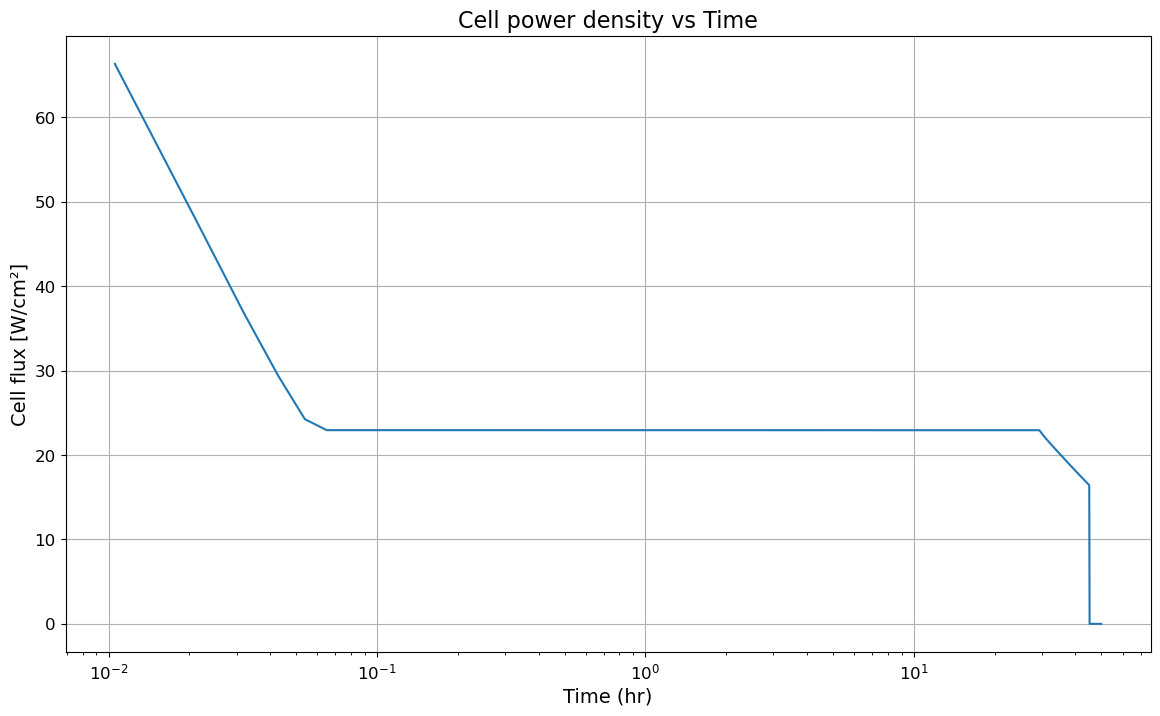

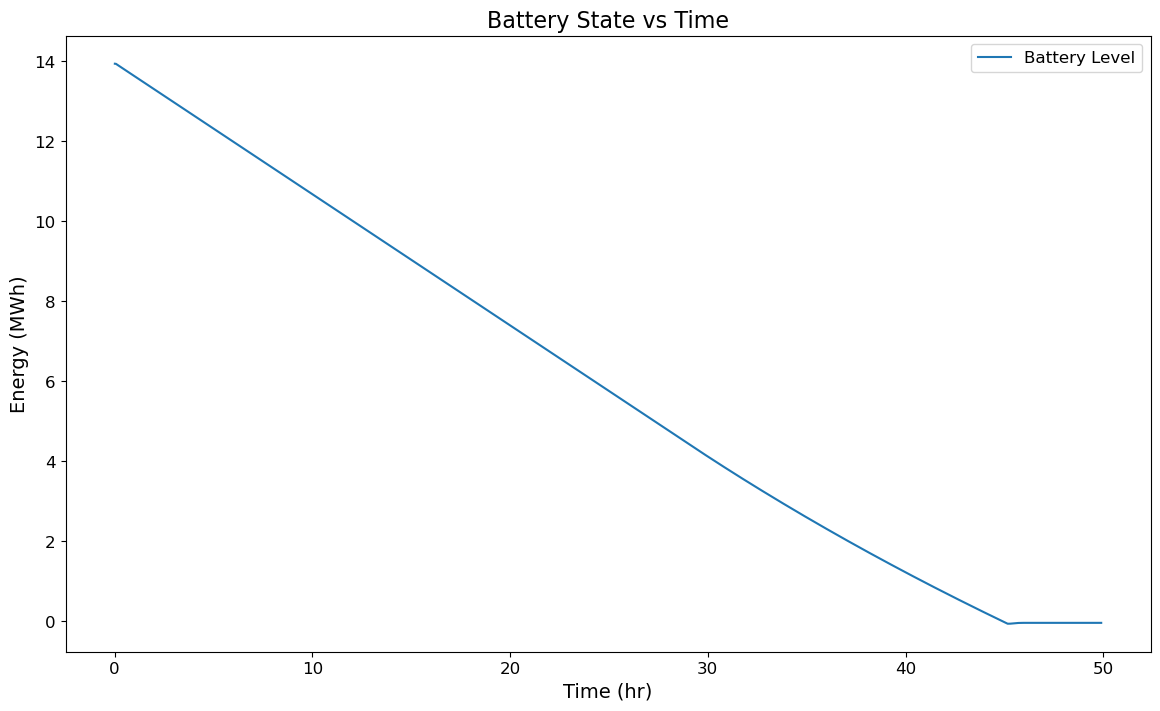

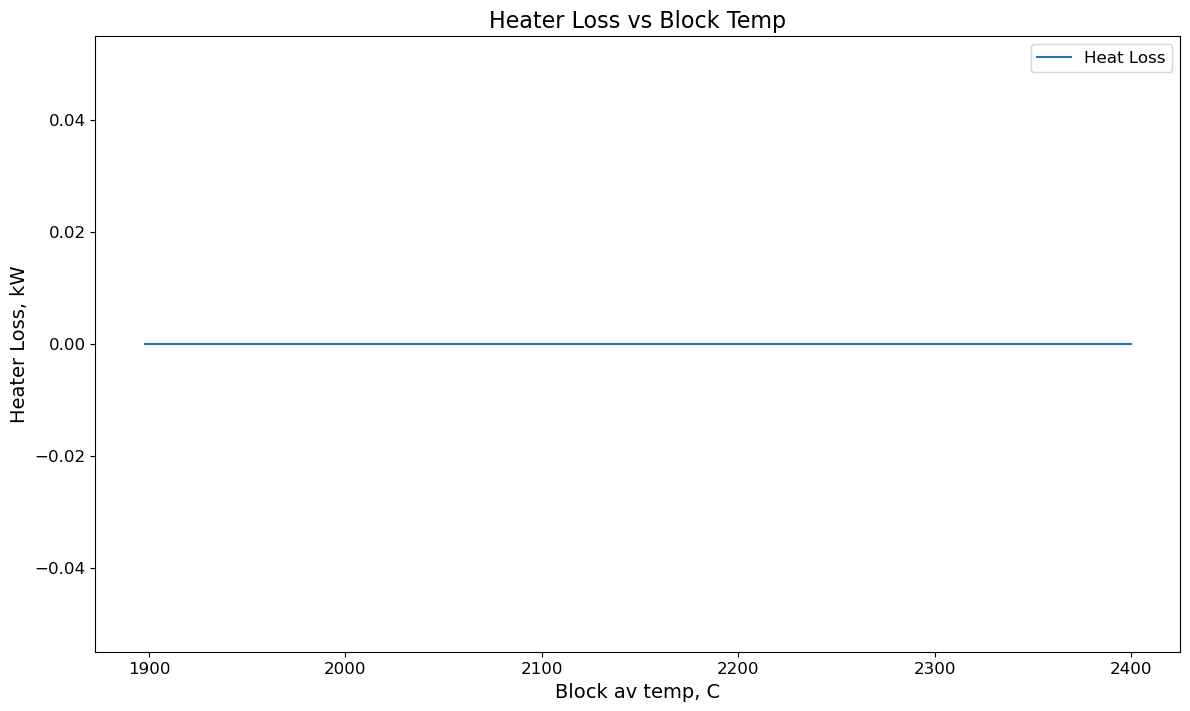

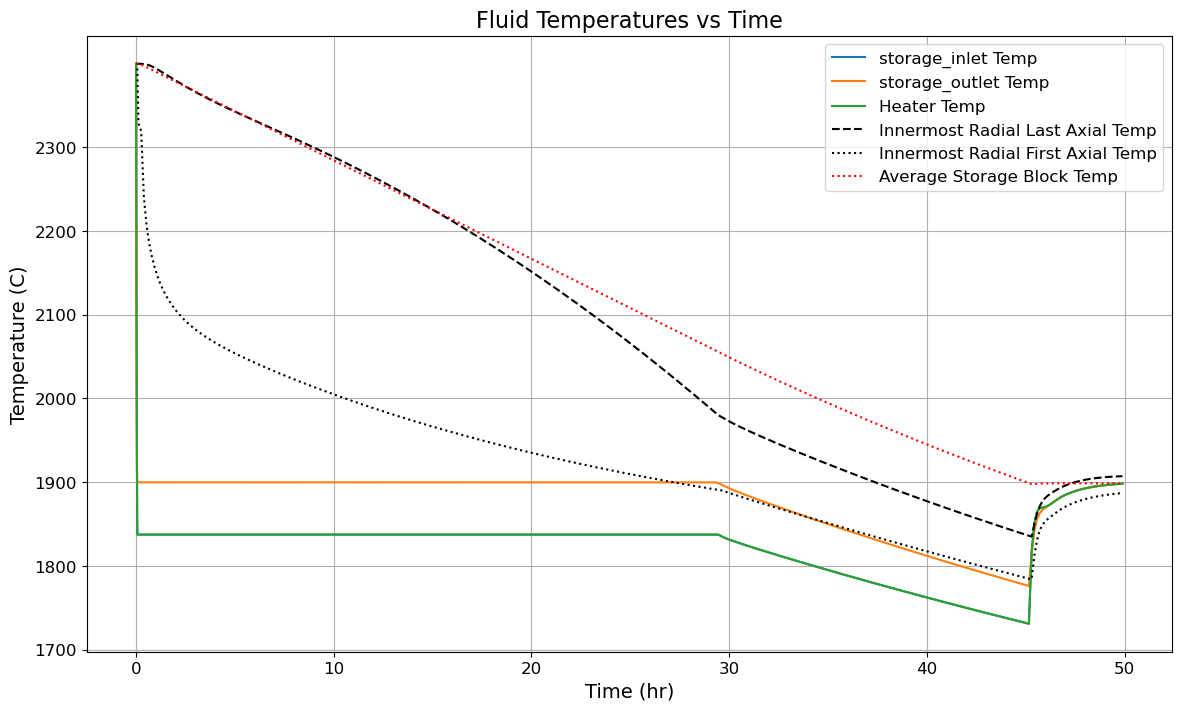

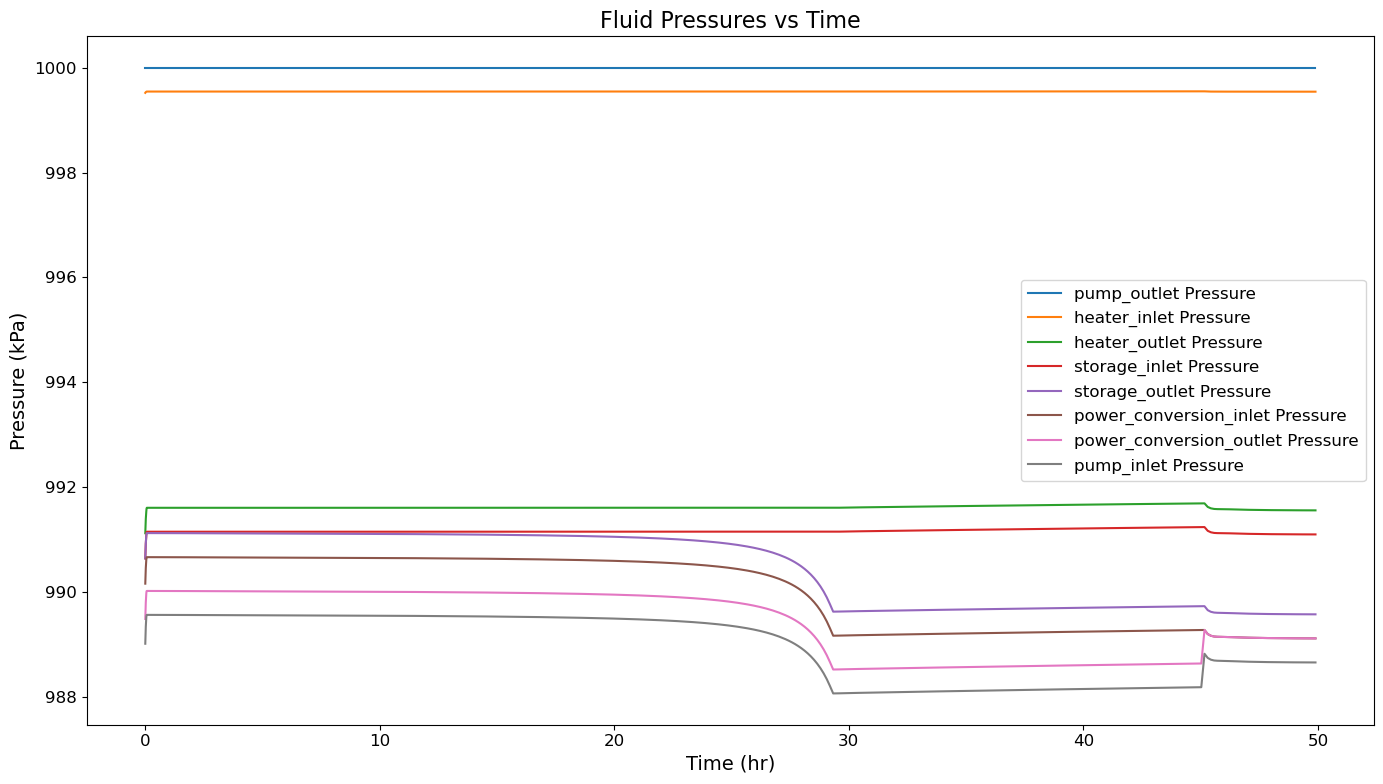

In [4]:
import imageio.v2 as imageio
import os
import shutil
def plot_temperature_distribution(temp_dist, time, length, r_inner, r_outer, vmin, vmax, filename):
    """
    Plot the temperature distribution as a 2D colormap.
    
    Parameters:
    temp_dist (2D array): Temperature distribution in the storage block (K).
    length (float): Length of the storage block (m).
    r_inner (float): Internal radius of the storage block (m).
    r_outer (float): External radius of the storage block (m).
    vmin (float): Minimum temperature value for the colormap.
    vmax (float): Maximum temperature value for the colormap.
    """
    temp_dist = np.transpose(temp_dist)
    num_rad_segments, num_ax_segments = temp_dist.shape
    dr = (r_outer - r_inner) / num_rad_segments
    dz = length / num_ax_segments
    r = np.linspace(r_inner + dr / 2, r_outer - dr / 2, num_rad_segments)
    z = np.linspace(dz / 2, length - dz / 2, num_ax_segments)
    R, Z = np.meshgrid(r, z, indexing='ij')
    cbarticks = np.arange(np.floor(vmin/100) * 100, np.ceil(vmax / 100) * 100, (np.ceil(vmax / 100) - np.floor(vmin/100)) * 5)
    plt.figure(figsize=(10, 6))
    plt.contourf(Z, R, temp_dist, cbarticks, cmap='hot', vmin=vmin, vmax=vmax)
    plt.colorbar(label='Temperature (C)', ticks = cbarticks)
    plt.xlabel('Axial Position (m)')
    plt.ylabel('Radial Position (m)')
    plt.title(f'Temperature Distribution in the Storage Block at t={time: .2f} hrs')
    plt.savefig(filename)
    plt.close()
    #plt.show()

def create_new_folder(base_folder='plots', label='plot'):
    """Creates a new folder with an incremented number in the base folder."""
    if not os.path.exists(base_folder):
        os.makedirs(base_folder)
    
    # Get the list of existing folders
    existing_folders = [f for f in os.listdir(base_folder) if os.path.isdir(os.path.join(base_folder, f))]
    # Extract numbers from folder names
    existing_numbers = [int(folder.split('_')[-1]) for folder in existing_folders if folder.startswith(f'{label}_')]
    # Determine the new folder number
    new_number = max(existing_numbers, default=0) + 1
    
    # Create the new folder
    new_folder = os.path.join(base_folder, f'{label}_{new_number}')
    os.makedirs(new_folder)
    
    return new_folder

def copy_yaml_file(folder, yaml_file='simulation_input_template.yaml'):
    """Copies the YAML file to the specified folder."""
    if os.path.exists(yaml_file):
        shutil.copy(yaml_file, folder)
    else:
        print(f"YAML file '{yaml_file}' not found.")

# Process the results and generate plots
time = np.array(results["time"]) / 3600  # Convert time to hours
# Extract data for plotting
pump_power = results["pump_power"]
heater_temp = np.array(results["heater_temp"]) - 273.15
heater_power = np.array(results["heater_power"]) / 1000 #convert to kW
power_generated = np.array(results["power_generated"]) / 1000  # Convert to kW
waste_heat = np.array(results["waste_heat"]) / 1000  # Convert to kW
pipe_heat_loss = np.array(results["Pipe_heat_loss"]) / 1000  # Convert to kW
Q_storage = np.array(results["Q_storage"]) / 1000  # Convert to kW
Q_tin = np.array(results["Q_tin"]) / 1000  # Convert to kW
batt_level = np.array(results["batt_level"])
flowrate = np.array(results["flowrate"])

# Extract the temperature of the innermost radial, last axial step storage block cell
num_iterations = len(results["time"])
innermost_radial_last_axial_temp = np.array([results["storage_temp_dist"][iteration][-1, 0] for iteration in range(num_iterations)]) - 273.15
innermost_radial_first_axial_temp = np.array([results["storage_temp_dist"][iteration][0, 0] for iteration in range(num_iterations)]) - 273.15
# Calculate the average storage block temperature
#average_storage_temp = np.array([np.mean(results["storage_temp_dist"][iteration]) for iteration in range(num_iterations)]) - 273.15
average_storage_temp = np.array(results["T_av_storage"]) - 273.15
# Calculate the integral of Q_storage with non-static iteration duration
iteration_durations = np.diff(np.array(results["time"]))
Q_storage_integral = np.cumsum(Q_storage[1:] * iteration_durations)
Q_block_full = V_storage * DT_batt * storage_cp(2448) * storage_rho(2448) / 1000
print(Q_storage_integral[-1]/3.6e6, max(batt_level), Q_block_full/3.6e6)
Electricity_integral = np.cumsum(power_generated[:-1] * iteration_durations)

# Extract fluid temperatures and pressures
fluid_labels_pressure = ["pump_outlet", "heater_inlet", "heater_outlet", "storage_inlet", "storage_outlet", "power_conversion_inlet", "power_conversion_outlet", "pump_inlet"]
fluid_labels_temp = ["storage_inlet","storage_outlet"]
fluid_temps = {label: [] for label in fluid_labels_temp}
fluid_pressures = {label: [] for label in fluid_labels_pressure}
# Determine the global min and max temperatures for consistent colormap scaling
vmin = np.min(results["storage_temp_dist"]) - 273.15
vmax = np.max(results["storage_temp_dist"]) - 273.15

block_params = {k: v for k, v in input_data["storage"]["Block"].items() if k != "initial_temp"}
V_storage = input_data["storage"]["Volume"]
N_blocks = input_data["storage"]["N_pipes"]
inner_radius = input_data["storage"]["Block"]["inner_radius"]
length = input_data["storage"]["Block"]["length"]
outer_radius = np.sqrt(V_storage / (N_blocks * length * np.pi) + inner_radius**2)
block_params["outer_radius"] = outer_radius
filenames = []
n_frames = 72
# Create a new folder to save the plots
new_folder = create_new_folder()
# Copy the YAML file to the new folder
copy_yaml_file(new_folder)
# Iterate over the actual number of simulation iterations
for iteration in range(num_iterations):
    for label in fluid_labels_temp:
        fluid_temps[label].append(results["fluid_conditions"][label][iteration].temperature)
    for label in fluid_labels_pressure:
        fluid_pressures[label].append(results["fluid_conditions"][label][iteration].pressure / 1000)

    # Plot storage temperature distribution over n frames
    current_time = time[iteration]
    if iteration == 0 or np.ceil(time[iteration]) > np.ceil(time[iteration - 1]):#  % np.round(time_steps / n_frames) == 0:
        filename = os.path.join(new_folder, f'storage_temp_dist_{np.round(current_time, 0)}.png')
        plot_temperature_distribution(
            results["storage_temp_dist"][iteration] - 273.15, np.round(current_time, 0),
            block_params["length"], 
            block_params["inner_radius"], 
            block_params["outer_radius"], vmin, vmax, filename
        )
        filenames.append(filename)

# Create GIF from the storage temperature distribution images
gif_path = os.path.join(new_folder, 'storage_temp_dist.gif')
with imageio.get_writer(gif_path, mode='I', duration=10) as writer:
    for filename in filenames:
        image = imageio.imread(filename)
        writer.append_data(image)

# Convert lists to numpy arrays for plotting
for label in fluid_labels_temp:
    fluid_temps[label] = np.array(fluid_temps[label]) - 273.15
for label in fluid_labels_pressure:
    fluid_pressures[label] = np.array(fluid_pressures[label])

# Create plots
#set default plot format
plt.rc('font', size=12)          # Default text size
plt.rc('axes', titlesize=16)     # Axes title size
plt.rc('axes', labelsize=14)     # Axes labels size
plt.rc('xtick', labelsize=12)    # X-tick labels size
plt.rc('ytick', labelsize=12)    # Y-tick labels size
plt.rc('legend', fontsize=12)    # Legend font size

# Plot pump power
plt.figure(figsize=(14, 8))
plt.plot(time[1:], pump_power[1:])
plt.xlabel('Time (hr)')
plt.ylabel('Pump Power (W)')
plt.title('Pump Power vs Time')
plot_path = os.path.join(new_folder, 'pump_power.png')
plt.savefig(plot_path)

# Plot heater temperature
plt.figure(figsize=(14, 8))
plt.plot(time, heater_temp)
plt.xlabel('Time (hr)')
plt.ylabel('Heater Temperature (C)')
plt.title('Heater Temperature vs Time')
plt.savefig(os.path.join(new_folder, 'heater_temp.png'))

# Plot waste heat, electricity, pipe heat loss, heat input, and Q_storage
plt.figure(figsize=(14, 8))
plt.plot(time, waste_heat + power_generated, label='Q_powerstick')
plt.plot(time, power_generated, label='Electricl Power')
#plt.plot(time, pipe_heat_loss, label='Heat Loss')
#plt.plot(time, heater_power, label='Heat Input')
#plt.plot(time, Q_storage, label='Q_storage')
#plt.plot(time, Q_tin, label='Q_tin')
plt.xlabel('Time (hr)')
plt.ylabel('Energy (kW)')
plt.title('Energy Flow vs Time')
plt.xscale('log')
plt.legend()
plt.savefig(os.path.join(new_folder, 'energy_flow.png'))

# Plot cell flux density
_cell_area_cm2 = (4 * float(input_data['power_conversion']['width_powerstick'])
                  * float(input_data['power_conversion']['length'])
                  * (1 - input_data['power_conversion']['f_bare'])
                  * input_data['power_conversion']['f_active']
                  * int(input_data['power_conversion']['N_cells']) * 1e4)  # cm2
cell_flux_wcm2 = np.array(results['cell_flux']) / _cell_area_cm2
plt.figure(figsize=(14, 8))
plt.plot(time, cell_flux_wcm2)
plt.xscale('log')
plt.xlabel('Time (hr)')
plt.ylabel('Cell flux [W/cm²]')
plt.title('Cell power density vs Time')
plt.grid(True)
plt.savefig(os.path.join(new_folder, 'cell_flux.png'))

# Slide 12: Integral of Q Storage Plot
plt.figure(figsize=(14, 8))
#plt.plot(time[:-1], Q_storage_integral / 3.6e6, label='Stored Energy')
plt.plot(time[:], batt_level, label='Battery Level')
plt.xlabel('Time (hr)')
plt.ylabel('Energy (MWh)')
plt.title('Battery State vs Time')
plt.legend()
plt.savefig(os.path.join(new_folder, 'storage_energy.png'))

# Slide 12: Integral of Q Storage Plot
plt.figure(figsize=(14, 8))
plt.plot(average_storage_temp, pipe_heat_loss, label='Heat Loss')
#plt.plot(fluid_temps["heater_inlet"], heater_power, label='Power')
plt.xlabel('Block av temp, C')
plt.ylabel('Heater Loss, kW')
plt.title('Heater Loss vs Block Temp')
plt.legend()
plt.savefig(os.path.join(new_folder, 'flowrate.png'))

# Plot fluid temperatures
plt.figure(figsize=(14, 8))
for label in fluid_labels_temp:
    plt.plot(time, fluid_temps[label], label=f'{label} Temp')
if simple_heater_bool == False:
    plt.plot(time, heater_temp, label='Heater Temp')
plt.plot(time, innermost_radial_last_axial_temp, label='Innermost Radial Last Axial Temp', linestyle='--', color='black')
plt.plot(time, innermost_radial_first_axial_temp, label='Innermost Radial First Axial Temp', linestyle=':', color='black')
plt.plot(time, average_storage_temp, label='Average Storage Block Temp', linestyle=':', color='red')
plt.xlabel('Time (hr)')
plt.ylabel('Temperature (C)')
plt.yticks(np.arange(np.floor(vmin / 100) * 100, np.ceil(vmax / 100) * 100, 100))
plt.title('Fluid Temperatures vs Time')
plt.legend(loc='best')
plt.grid(True)
plt.savefig(os.path.join(new_folder, 'Temperatures.png'))

# Plot fluid pressures
plt.figure(figsize=(14, 8))
for label in fluid_labels_pressure:
    plt.plot(time, fluid_pressures[label], label=f'{label} Pressure')
plt.xlabel('Time (hr)')
plt.ylabel('Pressure (kPa)')
plt.title('Fluid Pressures vs Time')
plt.legend()
plt.tight_layout()
#plt.show()
plt.savefig(os.path.join(new_folder, 'Pressures.png'))

# Calculate max temperature rise rate for storage block
max_storage_rise_rate = -np.inf
max_storage_rise_location = None
max_storage_rise_time = None

for i in range(num_iterations-1):
    temp_prev = results["storage_temp_dist"][i]
    temp_next = results["storage_temp_dist"][i+1]
    dt = results["time"][i+1] - results["time"][i]
    # Calculate rise rate for this step (K/s)
    rise_rate = (temp_next - temp_prev) / dt
    max_rise = np.max(rise_rate)
    if max_rise > max_storage_rise_rate:
        max_storage_rise_rate = max_rise
        # Find location (radial, axial) of max rise
        loc = np.unravel_index(np.argmax(rise_rate), rise_rate.shape)
        max_storage_rise_location = loc
        max_storage_rise_time = 0.5*(results["time"][i] + results["time"][i+1])

print(f"Max storage block temperature rise rate: {max_storage_rise_rate*60:.4f} K/min")
print(f"  at location (radial, axial): {max_storage_rise_location}")
print(f"  at time: {max_storage_rise_time/3600:.2f} hr")

# Calculate max temperature rise rate for each fluid temperature location
max_fluid_rise_rates = {}
max_fluid_rise_times = {}
for label in fluid_labels_temp:
    T = np.array([results["fluid_conditions"][label][i].temperature for i in range(num_iterations)])
    rise_rate = np.diff(T) / np.diff(results["time"])
    max_idx = np.argmax(rise_rate)
    max_fluid_rise_rates[label] = rise_rate[max_idx]
    max_fluid_rise_times[label] = 0.5*(results["time"][max_idx] + results["time"][max_idx+1])
    print(f"Max {label} temperature rise rate: {rise_rate[max_idx]*60:.4f} K/min at t = {max_fluid_rise_times[label]/3600:.2f} hr")

In [ ]:
# Run matrix of cases
# Load the input file
with open("simulation_input_template.yaml", "r") as file:
    input_data = yaml.safe_load(file)

# Helper function to generate time series from range definitions
def generate_time_series(range_definitions, time_steps):
    series = np.zeros(time_steps)
    for item in range_definitions:
        start, end = item['range']
        series[start:end+1] = item['value']
    return series

# Helper function to generate time series for emissivity table
def generate_emissivity_table_series(range_definitions, time_steps):
    series = [[] for _ in range(time_steps)]
    for item in range_definitions:
        start, end = item['range']
        for i in range(start, end+1):
            series[i] = [(tuple(pair[0]), float(pair[1]), float(pair[2]), float(pair[3])) for pair in item['value']]  # Ensure each entry is a list of tuples
    return series

# Helper function to generate uniform 2D temperature distribution
def generate_2d_temp_distribution(initial_temp, num_ax_segments, num_rad_segments):
    return np.full((num_ax_segments, num_rad_segments), initial_temp)

def create_new_folder(base_folder, label):
    """Creates a new folder with an incremented number in the base folder."""
    if not os.path.exists(base_folder):
        os.makedirs(base_folder)
    
    # Get the list of existing folders
    existing_folders = [f for f in os.listdir(base_folder) if os.path.isdir(os.path.join(base_folder, f))]
    
    # Extract numbers from folder names
    existing_numbers = [int(folder.split('_')[-1]) for folder in existing_folders if folder.startswith(f'{label}_')]
    
    # Determine the new folder number
    new_number = max(existing_numbers, default=0) + 1
    
    # Create the new folder
    new_folder = os.path.join(base_folder, f'{label}_{new_number}')
    os.makedirs(new_folder)
    
    return new_folder

def save_input_config(file_path, input_data):
    """
    Save the input configuration to a YAML file.
    
    Parameters:
    file_path (str): Path to the input configuration file.
    input_data (dict): Input configuration data.
    """
    with open(file_path, 'w') as file:
        yaml.dump(input_data, file)

def save_results(file_path, results):
    """
    Save the simulation results to a YAML file.
    
    Parameters:
    file_path (str): Path to the results file.
    results (dict): Simulation results data.
    """
    with open(file_path, 'w') as file:
        yaml.dump(results, file)

# Extract the parameters from the input file
time_steps = input_data["time_steps"]
end_time = input_data["end_time"]
heat_loss_bool = input_data["heat_loss_bool"]
simple_heater_bool = input_data["simple_heater_bool"]
vary_flowrate_bool = input_data["vary_flowrate_bool"]
N_loops_step = input_data["N_loops_step"]
print_outputs_bool = input_data["print_outputs_bool"]

emissivity_tables = generate_emissivity_table_series(input_data["emissivity_tables"], time_steps)
#power_bypass = generate_time_series(input_data["power_conversion_bypass_fractions"], time_steps)

initial_conditions = input_data["initial_fluids"]
N_stations = input_data["N_stations"]
T_sur = input_data["T_sur"]
# Create the components
pump = Pump(pump_efficiency=input_data["pump"]["efficiency"])

#define test cases
#heating_rates = [1]
#bypass_bools = [True, False]
#powerstick_lengths = [1, 1.5, 3]
#num_storage_blocks = [5,7,10]
num_blocks_per_row = [1, 2, 4, 6, 12]
base_block_length = 2.8
tot_num_blocks = 648
#block_in_rads = [0.03, .05, .08, 0.12, 0.18, 0.24, 0.30]
#block_in_rads = [0.03,0.15,0.3]
flow_rate_vals = [700,1400,3500]
#N_heater_pipes = [3, 6, 9]
#gas_dir_emis_vals = [0.05, 0.1, 0.2, 0.4, 0.8]
T_emitter_lims = [2523]
heating_rates = [1]
bypass_bools = [True]
#num_storage_blocks = [8, 16, 32]
#flow_rate_vals = [7.0, 21.0, 35.0]
powerstick_lengths = [3]
#num_storage_blocks = np.logspace(8,80,10)
# Directory to save input configurations
input_dir = "test_matrices"
os.makedirs(input_dir, exist_ok=True)
#results = np.empty((len(heating_rates), len(T_emitter_lims), len(num_storage_blocks), len(bypass_bools), len(flow_rate_vals)), dtype=object)
results = np.empty((len(num_blocks_per_row), len(flow_rate_vals)), dtype=object)
new_folder = create_new_folder(base_folder=input_dir, label='run')
#for i, heating_rate in enumerate(heating_rates):
for i, blocks_per_row in enumerate(num_blocks_per_row):
    for j, flow_rate_val in enumerate(flow_rate_vals):
    #for j, powerstick_length in enumerate(powerstick_lengths):
    #for j, block_in_rad in enumerate(block_in_rads):
        #for k, num_blocks in enumerate(num_storage_blocks):
        #    for m, bypass_bool in enumerate(bypass_bools):
        #        for n, flow_rate_val in enumerate(flow_rate_vals):
        #flow_rate_val = flow_rates[0]
        input_data["storage"]["N_pipes"] = int(tot_num_blocks / blocks_per_row)
        heating_rate = heating_rates[0]
        #num_blocks = num_storage_blocks[0]
        bypass_bool = bypass_bools[0]
        powerstick_length = powerstick_lengths[0]
        input_data["power_conversion"]["max_inlet_temp"] = T_emitter_lims[0]
        #for entry in input_data["emissivity_tables"]:
        #    for value in entry['value']:
        #        value[2] = gas_dir_emis_val
        #emissivity_tables = generate_emissivity_table_series(input_data["emissivity_tables"], time_steps)
        #reset initial fluids
                    #N_loops_step = int(flow_rate_val) #rough way to scale speed up to not induce instability
                    #N_loops_step = min(int(flow_rate_val), input_data["N_loops_step"])
        N_loops_step = input_data["N_loops_step"]
        initial_fluids = [Fluid(temperature=float(initial_conditions["temperature"]),
            pressure=float(initial_conditions["pressure"]),
            flow_rate=1) for _ in range(N_stations)]
        #update varied parameters
        input_data["heat_inputs"] = heat_inputs = [{"range": [0, input_data["time_steps"] - 1], "value": heating_rate}]
        #half_time_steps = time_steps // 2
        #input_data["heat_inputs"] = [{"range": [0, half_time_steps - 1], "value": heating_rate},
        #                             {"range": [half_time_steps, time_steps - 1], "value": 0}]
        input_data["flow_rates"] = flow_rates = [{"range": [0, input_data["time_steps"] - 1], "value": flow_rate_val}]
        input_data["power_conversion"]["length"] = powerstick_length
        #input_data["storage"]["N_pipes"] = num_blocks
        #input_data["storage"]["Block"]["inner_radius"] = block_in_rad
        input_data["bypass_bool"] = bypass_bool
        #generate input time series
        heat_inputs = generate_time_series(input_data["heat_inputs"], time_steps)
        flow_rates = generate_time_series(input_data["flow_rates"], time_steps)
        
        heater = HeatingModule(heat_input=input_data["heater"]["heat_input"], N_pipes=input_data["heater"]["N_pipes"],
                               Pipe=Pipe(**input_data["heater"]["Pipe"]), simple_heat=simple_heater_bool)
        pipe_template = Pipe(**input_data["storage"]["Pipe"])
        
        # Generate initial temperature distribution as a 2D array
        num_ax_segments = input_data["storage"]["num_ax_segments"]
        num_rad_segments = input_data["storage"]["num_rad_segments"]
        initial_temp = input_data["storage"]["Block"]["initial_temp"]
        initial_temp_distribution = generate_2d_temp_distribution(initial_temp, num_ax_segments, num_rad_segments)
        
        block_params = {k: v for k, v in input_data["storage"]["Block"].items() if k != "initial_temp"}
        
        storage_bypass_range = input_data["storage"]["Bypass"]["range"]
        V_storage = input_data["storage"]["Volume"]
        #N_blocks = input_data["storage"]["N_pipes"]
        length = input_data["storage"]["Block"]["length"]
        block_params["length"] = base_block_length * blocks_per_row
        block_in_rad = block_params["inner_radius"]
        outer_radius = np.sqrt(V_storage / (tot_num_blocks / blocks_per_row * length * np.pi) + block_in_rad**2)
        block_params["outer_radius"] = outer_radius
        storage = StorageModule(Block=GraphiteBlock(initial_temp_distribution, **block_params),  
                                N_pipes=input_data["storage"]["N_pipes"], 
                                Pipe=pipe_template, 
                                num_ax_segments=input_data["storage"]["num_ax_segments"], 
                                num_rad_segments=input_data["storage"]["num_rad_segments"],
                                bypass_range=storage_bypass_range)
        power_conversion = PowerConversionBlock(
            axial_steps=int(input_data["power_conversion"]["axial_steps"]),
            N_cells=int(input_data["power_conversion"]["N_cells"]),
            height_pipe=float(input_data["power_conversion"]["height_pipe"]),
            width_emitter=float(input_data["power_conversion"]["width_emitter"]),
            length=float(input_data["power_conversion"]["length"]),
            roughness_pipe=float(input_data["power_conversion"]["roughness_pipe"]),
            width_powerstick=float(input_data["power_conversion"]["width_powerstick"]),
            wall_thickness=float(input_data["power_conversion"]["wall_thickness"]),
            cooling_temp=float(input_data["power_conversion"]["cooling_temp"]),
            panel_efficiency=float(input_data["power_conversion"]["panel_efficiency"]),
            T_tin_max_PCB=input_data["power_conversion"]["max_inlet_temp"],
            f_bare=input_data["power_conversion"]["f_bare"],
            f_active=input_data["power_conversion"]["f_active"],
            emissivity_table=emissivity_tables[0]
            
        )
        pipes = [Pipe(**pipe) for pipe in input_data["pipes"]]
        
        # Create the system simulation
        simulation = SystemSimulation(pump, heater, storage, power_conversion, pipes, heat_loss_bool, bypass_bool, vary_flowrate_bool, print_outputs_bool, N_loops_step)
        # Run the simulation
        #print("Case: Heat rate:", heating_rate, "stick length:", powerstick_length, "num_blocks", num_blocks, "Bypass: ", bypass_bool, "flowrate: ", flow_rate_val)
        print("Case: Heat rate:", heating_rate, "num blocks per row:", blocks_per_row, "Max flowrate: ", flow_rate_val)
        result = simulation.run_simulation(initial_fluids, end_time, heat_inputs, flow_rates, emissivity_tables, T_sur)
        results[i, j] = result
        # Save the input configuration
        #file_name = f"input_hr{heating_rate}_pl{powerstick_length}_sb{num_blocks}.yaml"
        file_name = f"input_hr{heating_rate}_sbr{blocks_per_row}_fr{flow_rate_val}.yaml"
        file_path = os.path.join(new_folder, file_name)
        save_input_config(file_path, input_data)
        # Save the results
        results_file_name = f"results_hr{heating_rate}_sbr{blocks_per_row}_fr{flow_rate_val}.yaml"
        results_file_path = os.path.join(new_folder, results_file_name)
        save_results(results_file_path, result)
            


In [ ]:
# Case optimization
# Load the input file
with open("simulation_input_template.yaml", "r") as file:
    input_data = yaml.safe_load(file)

# Helper function to generate time series from range definitions
def generate_time_series(range_definitions, time_steps):
    series = np.zeros(time_steps)
    for item in range_definitions:
        start, end = item['range']
        series[start:end+1] = item['value']
    return series

# Helper function to generate time series for emissivity table
def generate_emissivity_table_series(range_definitions, time_steps):
    series = [[] for _ in range(time_steps)]
    for item in range_definitions:
        start, end = item['range']
        for i in range(start, end+1):
            series[i] = [(tuple(pair[0]), float(pair[1]), float(pair[2]), float(pair[3])) for pair in item['value']]  # Ensure each entry is a list of tuples
    return series

# Helper function to generate uniform 2D temperature distribution
def generate_2d_temp_distribution(initial_temp, num_ax_segments, num_rad_segments):
    return np.full((num_ax_segments, num_rad_segments), initial_temp)

def create_new_folder(base_folder, label):
    """Creates a new folder with an incremented number in the base folder."""
    if not os.path.exists(base_folder):
        os.makedirs(base_folder)
    
    # Get the list of existing folders
    existing_folders = [f for f in os.listdir(base_folder) if os.path.isdir(os.path.join(base_folder, f))]
    
    # Extract numbers from folder names
    existing_numbers = [int(folder.split('_')[-1]) for folder in existing_folders if folder.startswith(f'{label}_')]
    
    # Determine the new folder number
    new_number = max(existing_numbers, default=0) + 1
    
    # Create the new folder
    new_folder = os.path.join(base_folder, f'{label}_{new_number}')
    os.makedirs(new_folder)
    
    return new_folder

def save_input_config(file_path, input_data):
    """
    Save the input configuration to a YAML file.
    
    Parameters:
    file_path (str): Path to the input configuration file.
    input_data (dict): Input configuration data.
    """
    with open(file_path, 'w') as file:
        yaml.dump(input_data, file)

def save_results(file_path, results):
    """
    Save the simulation results to a YAML file.
    
    Parameters:
    file_path (str): Path to the results file.
    results (dict): Simulation results data.
    """
    with open(file_path, 'w') as file:
        yaml.dump(results, file)
        
# Function to check if the system reaches full charge
def is_fully_charged(results, target_state):
    """
    Check if the system reaches the full charge condition.
    Modify this function to reflect your definition of 'fully charged' (e.g., temperature, energy).
    """
    final_batt_level = np.array(results["batt_level"])[-1] / (V_storage * DT_batt * storage_cp(2448) * storage_rho(2448) / 3.6e9)
    print("final batt level: ", final_batt_level)
    # Example: Check if the final state variable (e.g., energy or temperature) meets or exceeds the target
    return final_batt_level >= target_state

# Binary search to find the minimum heating rate
def find_min_heating_rate(simulation, initial_fluids, end_time, flow_rates, emissivity_tables, T_sur, time_steps, input_data, target_state):
    low = 1e5  # Minimum heating rate (arbitrary starting point)
    high = 1e6  # Maximum heating rate (arbitrary high value)
    tolerance = 1e3  # Stop when the difference between high and low is less than this value
    best_heating_rate = None  # To store the lowest heating rate that meets the target
    while high - low > tolerance:
        mid = (low + high) / 2
        # Reset fluid temperatures and pressures for this test
        initial_fluids = [Fluid(temperature=float(initial_conditions["temperature"]),
        pressure=float(initial_conditions["pressure"]),
        flow_rate=1) for _ in range(N_stations)]

        # Reset storage block temperatures for this test
        num_ax_segments = input_data["storage"]["num_ax_segments"]
        num_rad_segments = input_data["storage"]["num_rad_segments"]
        initial_temp = input_data["storage"]["Block"]["initial_temp"]
        initial_temp_distribution = generate_2d_temp_distribution(initial_temp, num_ax_segments, num_rad_segments)
        
        block_params = {k: v for k, v in input_data["storage"]["Block"].items() if k != "initial_temp"}
        
        storage_bypass_range = input_data["storage"]["Bypass"]["range"]
        V_storage = input_data["storage"]["Volume"]
        #N_blocks = input_data["storage"]["N_pipes"]
        inner_radius = input_data["storage"]["Block"]["inner_radius"]
        length = input_data["storage"]["Block"]["length"]
        outer_radius = np.sqrt(V_storage / (num_blocks * length * np.pi) + inner_radius**2)
        block_params["outer_radius"] = outer_radius
        storage = StorageModule(Block=GraphiteBlock(initial_temp_distribution, **block_params),  
                                N_pipes=input_data["storage"]["N_pipes"], 
                                Pipe=pipe_template, 
                                num_ax_segments=input_data["storage"]["num_ax_segments"], 
                                num_rad_segments=input_data["storage"]["num_rad_segments"],
                                bypass_range=storage_bypass_range)

        # Update the heating rate in the input data
        input_data["heat_inputs"] = [{"range": [0, time_steps - 1], "value": mid}]
        heat_inputs = generate_time_series(input_data["heat_inputs"], time_steps)
        
        #print("heat input: ",mid, "fluid temp: ",initial_fluids[0].temperature, "block temp: ",initial_temp)
        # Run the simulation
        simulation = SystemSimulation(pump, heater, storage, power_conversion, pipes, heat_loss_bool, bypass_bool, vary_flowrate_bool, print_outputs_bool, N_loops_step)
        results = simulation.run_simulation(initial_fluids, end_time, heat_inputs, flow_rates, emissivity_tables, T_sur)
        final_batt_level = np.array(results["batt_level"])[-1] / (V_storage * 500 * storage_cp(2448) * storage_rho(2448) / 3.6e9)
        print(low,mid,high,final_batt_level,target_state)
        # Check if the system is fully charged
        if is_fully_charged(results, target_state):
            # If fully charged, continue with bisection
            best_heating_rate = mid
            high = mid
        else:
            # If not fully charged, switch to adaptive search
            # Calculate the error as the difference between the target and the actual value
            #final_batt_level = np.array(results["batt_level"])[-1] / (V_storage * 500 * storage_cp(2448) * storage_rho(2448) / 3.6e9)
            error = target_state - final_batt_level

            # Dynamically adjust the step size based on the error
            step_size = max(tolerance, abs(error) * 1e5)  # Scale the step size with the error

            # Update the lower bound based on the adaptive step size
            low = min(mid + step_size, high)
    # Handle cases where no valid heating rate is found
    if best_heating_rate is None:
        print(f"Warning: No heating rate found to fully charge the system within the allowable range.")
        return high, results
    # Return the minimum heating rate that results in full charge
    return best_heating_rate or low, results

target_state = 0.98
# Extract the parameters from the input file
time_steps = input_data["time_steps"]
print(time_steps)
end_time = input_data["end_time"]
heat_loss_bool = input_data["heat_loss_bool"]
simple_heater_bool = input_data["simple_heater_bool"]
vary_flowrate_bool = input_data["vary_flowrate_bool"]
bypass_bool = input_data["bypass_bool"]
N_loops_step = input_data["N_loops_step"]
print_outputs_bool = input_data["print_outputs_bool"]

emissivity_tables = generate_emissivity_table_series(input_data["emissivity_tables"], time_steps)

initial_conditions = input_data["initial_fluids"]
N_stations = input_data["N_stations"]
T_sur = input_data["T_sur"]
# Create the components
pump = Pump(pump_efficiency=input_data["pump"]["efficiency"])

#heating_rates = [250000, 500000, 750000]
#num_storage_blocks = [1,2,3,4,5,6,8,10,15,20,30,40]
num_storage_blocks = [7]
# Directory to save input configurations
input_dir = "test_matrices"
os.makedirs(input_dir, exist_ok=True)
results = np.empty(len(num_storage_blocks), dtype=object)
result_rates = np.empty(len(num_storage_blocks))
new_folder = create_new_folder(base_folder=input_dir, label='run')
for i, num_blocks in enumerate(num_storage_blocks):
    N_loops_step = input_data["N_loops_step"]
    initial_fluids = [Fluid(temperature=float(initial_conditions["temperature"]),
        pressure=float(initial_conditions["pressure"]),
        flow_rate=1) for _ in range(N_stations)]
    #update varied parameters
    #input_data["heat_inputs"] = heat_inputs = [{"range": [0, input_data["time_steps"] - 1], "value": heating_rate}]
    input_data["storage"]["N_pipes"] = num_blocks
    #generate input time series
    heat_inputs = generate_time_series(input_data["heat_inputs"], time_steps)
    
    heater = HeatingModule(heat_input=input_data["heater"]["heat_input"], N_pipes=input_data["heater"]["N_pipes"],
                           Pipe=Pipe(**input_data["heater"]["Pipe"]), simple_heat=simple_heater_bool)
    pipe_template = Pipe(**input_data["storage"]["Pipe"])
    
    # Generate initial temperature distribution as a 2D array
    num_ax_segments = input_data["storage"]["num_ax_segments"]
    num_rad_segments = input_data["storage"]["num_rad_segments"]
    initial_temp = input_data["storage"]["Block"]["initial_temp"]
    initial_temp_distribution = generate_2d_temp_distribution(initial_temp, num_ax_segments, num_rad_segments)
    
    block_params = {k: v for k, v in input_data["storage"]["Block"].items() if k != "initial_temp"}
    
    storage_bypass_range = input_data["storage"]["Bypass"]["range"]
    V_storage = input_data["storage"]["Volume"]
    #N_blocks = input_data["storage"]["N_pipes"]
    inner_radius = input_data["storage"]["Block"]["inner_radius"]
    length = input_data["storage"]["Block"]["length"]
    outer_radius = np.sqrt(V_storage / (num_blocks * length * np.pi) + inner_radius**2)
    block_params["outer_radius"] = outer_radius
    storage = StorageModule(Block=GraphiteBlock(initial_temp_distribution, **block_params),  
                            N_pipes=input_data["storage"]["N_pipes"], 
                            Pipe=pipe_template, 
                            num_ax_segments=input_data["storage"]["num_ax_segments"], 
                            num_rad_segments=input_data["storage"]["num_rad_segments"],
                            bypass_range=storage_bypass_range)
    
    power_conversion = PowerConversionBlock(
        axial_steps=int(input_data["power_conversion"]["axial_steps"]),
        N_cells=int(input_data["power_conversion"]["N_cells"]),
        height_pipe=float(input_data["power_conversion"]["height_pipe"]),
        width_emitter=float(input_data["power_conversion"]["width_emitter"]),
        length=float(input_data["power_conversion"]["length"]),
        roughness_pipe=float(input_data["power_conversion"]["roughness_pipe"]),
        width_powerstick=float(input_data["power_conversion"]["width_powerstick"]),
        wall_thickness=float(input_data["power_conversion"]["wall_thickness"]),
        cooling_temp=float(input_data["power_conversion"]["cooling_temp"]),
        panel_efficiency=float(input_data["power_conversion"]["panel_efficiency"]),
        T_tin_max_PCB=input_data["power_conversion"]["max_inlet_temp"],
        f_bare=input_data["power_conversion"]["f_bare"],
        f_active=input_data["power_conversion"]["f_active"],
        emissivity_table=emissivity_tables[0]
        
    )
    pipes = [Pipe(**pipe) for pipe in input_data["pipes"]]
    
    # Create the system simulation
    simulation = SystemSimulation(pump, heater, storage, power_conversion, pipes, heat_loss_bool, bypass_bool, vary_flowrate_bool, N_loops_step)
    # Run the simulation
    print("Case: num_blocks", num_blocks)
    min_heating_rate, result = find_min_heating_rate(simulation, initial_fluids, end_time, flow_rates, emissivity_tables, 
                                                       input_data["T_sur"], time_steps, input_data, target_state)
    print(f"Minimum heating rate for {num_blocks} blocks: {min_heating_rate} W")
    result_rates[i] = min_heating_rate
    results[i] = result
    #results[i] = simulation.run_simulation(initial_fluids, end_time, heat_inputs, flow_rates, emissivity_tables, T_sur)
    # Save the input config
    # Save the input configuration
    file_name = f"input_sb{num_blocks}.yaml"
    file_path = os.path.join(new_folder, file_name)
    save_input_config(file_path, input_data)
    # Save the results
    results_file_name = f"results_sb{num_blocks}.yaml"
    results_file_path = os.path.join(new_folder, results_file_name)
    save_results(results_file_path, results[i])
            
# Plot the results
plt.figure(figsize=(10, 6))
plt.plot(num_storage_blocks, result_rates, marker='o', linestyle='-', color='b', label='Heating Rate')

# Add labels and title
plt.xlabel('Number of Storage Blocks')
plt.ylabel('Heating Rate (W)')
plt.title('Heating Rates vs. Number of Storage Blocks')
plt.grid(True)
plt.legend()

# Show the plot
plt.show()

In [ ]:
import re
with open("simulation_input_template.yaml", "r") as file:
    input_data = yaml.safe_load(file)
def process_results_matrix(results, end_time, target_state):
    time = np.array(results["time"]) / 3600  # Convert time to hours
    num_iterations = len(results["time"])
    # Extract data for plotting
    data_streams = {
        "time": time,
        "pump_power": np.array(results["pump_power"]),
        "heater_temp": np.array(results["heater_temp"]) - 273.15,
        "heater_power": np.array(results["heater_power"]) / 1000,  # Convert to kW
        "power_generated": np.array(results["power_generated"]) / 1000,  # Convert to kW
        "waste_heat": np.array(results["waste_heat"]) / 1000,  # Convert to kW
        "pipe_heat_loss": np.array(results["Pipe_heat_loss"]) / 1000,  # Convert to kW
        "Q_storage": np.array(results["Q_storage"]) / 1000,  # Convert to kW
        "Q_tin": np.array(results["Q_tin"]) / 1000,  # Convert to kW
        "Batt_level": np.array(results["batt_level"])
    }
    # Extract the temperature of the innermost radial, last axial step storage block cell
    data_streams["innermost_radial_last_axial_temp"] = np.array([results["storage_temp_dist"][iteration][-1, 0] for iteration in range(num_iterations)]) - 273.15
    # Calculate the average storage block temperature
    data_streams["average_storage_temp"] = np.array([np.mean(results["storage_temp_dist"][iteration]) for iteration in range(num_iterations)]) - 273.15
    # Calculate the integral of Q_storage with non-static iteration duration
    Q_block_full = V_storage * 500 * storage_cp(2448) * storage_rho(2448) / 3.6e9
    iter_full = np.where(np.array(results["batt_level"])/ Q_block_full > target_state)[0]
    if iter_full.size == 0: #battery doesn't reach threshhold
        #time_full = np.array(data_streams["time"])[-1]
        time_full = 0
    else:
        time_full = np.array(data_streams["time"])[iter_full[0]]
    print("batt charge time: ", time_full)
    iteration_durations = np.diff(np.array(results["time"]))
    #Q_block_init = Q_block_full #0 for charging, Q_block_full for discharging
    Q_block_init = 0
    iteration_durations = np.append(iteration_durations, end_time - results["time"][-1])
    data_streams["Q_storage_integral"] = (Q_block_init + np.cumsum(data_streams["Q_storage"] * iteration_durations)) / Q_block_full
    data_streams["Electricity_integral"] = np.cumsum(data_streams["power_generated"] * iteration_durations)
    data_streams["Batt_level"] = (Q_block_init  + data_streams["Batt_level"]) / Q_block_full

    return data_streams,time_full

def downsample_data(data_streams, num_points=100):
    indices = np.linspace(0, len(data_streams["time"]) - 1, num_points).astype(int)
    downsampled_streams = {}
    for key, value in data_streams.items():
        if isinstance(value, np.ndarray) and len(value) > 1:
            downsampled_streams[key] = value[indices]
        else:
            downsampled_streams[key] = value# Keep scalars or incompatible arrays as is
    return downsampled_streams

def generate_handles(vary_param, param_values, fixed_params):
    handles = []
    for val in param_values:
        # Find the matching result for the current param value
        for result in all_results:
            if precise_match(result["label"], {**fixed_params, vary_param: val}):
                handles.append(plt.Line2D([0], [0], linestyle=result["line_style"], color=result["color"], marker=result["shape"], markersize=result["size"], label=f'{vary_param}={val}'))
                break
        
    return handles

def precise_match(label, fixed_params):
    # Create a regex pattern to match the exact parameter values
    for k, v in fixed_params.items():
        pattern = rf"{k}={v},"
        if not re.search(pattern, label):
            return False
    return True
        
def plot_results(all_params, vary_param, file_suffix):
    fixed_params = {k: v for k, v in all_params.items() if k != vary_param}
    fixed_params_str = ', '.join([f"{k}={v}" for k, v in fixed_params.items()])
    #print(f"Fixed parameters: {fixed_params}")  # Debugging print statement
    plt.figure()
    first_entry = True
    for result in all_results:
        if precise_match(result["label"], fixed_params):
            #print(f"Matched result with label: {result['label']}")  # Debugging print statement for matches
            time = result["data_streams"]["time"]
            Batt_level = result["data_streams"]["Batt_level"]
            plt.plot(time, Batt_level, linestyle=result["line_style"], color=result["color"], marker=result["shape"],
                     markersize=result["size"], label=result["label"] if first_entry else "")
            first_entry = False

    # Adding legend for the varying parameter
    handles = generate_handles(vary_param, param_values, fixed_params)
    plt.legend(handles=handles, loc='best')

    plt.xlabel("Time (hours)")
    plt.ylabel("Battery Charge State")
    plt.title(f"Battery State: {fixed_params_str}")
    plt.savefig(os.path.join(new_folder, f'Battery_Charge_State_{file_suffix}.png'))

    plt.figure()
    first_entry = True
    for result in all_results:
        if precise_match(result["label"], fixed_params):
            print(f"Matched result with label: {result['label']}")  # Debugging print statement for matches
            time = result["data_streams"]["time"]
            Q_powerstick = result["data_streams"]["power_generated"] + result["data_streams"]["waste_heat"]
            plt.plot(time, Q_powerstick, linestyle=result["line_style"], color=result["color"], marker=result["shape"], 
                     markersize=result["size"], label=result["label"] if first_entry else "")
            first_entry = False

    plt.legend(handles=handles, loc='best')
    plt.xlabel("Time (hours)")
    plt.ylabel("Q_powerstick")
    plt.title("Q_powerstick vs. Time")
    plt.savefig(os.path.join(new_folder, f'Q_powerstick_{file_suffix}.png'))

def plot_battery_full_times(time_full, heating_rates, num_storage_blocks, block_in_rads, output_folder):
    """
    Plot the times at which the battery becomes full for each condition, grouped by heating rate,
    excluding points where the value is 0.

    Parameters:
        time_full (numpy.ndarray): Array of times at which the battery becomes full (indexed by heating rate and block in radius).
        heating_rates (list): List of heating rates.
        block_in_rads (list): List of block in radii.
        output_folder (str): Folder to save the output plot.
    """
    plt.figure()
    
    
    # Loop through each heating rate and plot the corresponding times
    for i, heating_rate in enumerate(heating_rates):
        for j, num_blocks in enumerate(num_storage_blocks):
        # Get the times and radii for the current heating rate
            #times = time_full[i, :, j, 0, 0]
            times = time_full[i,j]
            print(heating_rate, num_blocks,times)
            area_ratios = np.array(block_in_rads) / (0.5 * input_data["storage"]["Pipe"]["OD"])
            
            # Filter out points where time is 0
            valid_indices = times > 0
            filtered_times = times[valid_indices]
            filtered_AR = np.array(area_ratios)[valid_indices]
            
            # Plot the filtered data
            plt.plot(filtered_AR, filtered_times, label=f'HR={heating_rate}, SB={num_blocks}', marker='o', linestyle=linestyles[j], color=colors[i] )
    
    plt.xlabel("Area Ratio")
    plt.ylabel("Time to Full Battery (hours)")
    plt.title("Time to Full Battery vs. Area Ratio")
    plt.legend(fontsize=8,loc='best')
    plt.grid(True)
    
    # Save the plot
    plt.savefig(os.path.join(output_folder, 'Time_to_Full_Battery.png'))
    print(f"Plot saved as 'Time_to_Full_Battery.png' in {output_folder}")
    
# Initialize arrays to store results
all_labels = []
all_results = []
time_full = np.empty_like(results)
target_state = 0.98 #threshhold battery level

# Directory containing the results files
results_dir = new_folder
# Define the symbol shapes, sizes, and colors
shapes = ['o', 's', '^']  # Circle, square, and triangle for powerstick lengths
linestyles = ['-', '--', ':', '-.']
sizes = [8, 12, 15]  # Different sizes for block numbers
colors = ['r', 'g', 'b', 'k', 'c']  # Red, green, and blue for heating rates

for i, blocks_per_row in enumerate(num_blocks_per_row):
#for i, heating_rate in enumerate(heating_rates):
    #for j, block_in_rad in enumerate(block_in_rads):
    for j, flow_rate_val in enumerate(flow_rate_vals):
        #for k, num_blocks in enumerate(num_storage_blocks):
            #for m, bypass_bool in enumerate(bypass_bools):
                #for n, flow_rate_val in enumerate(flow_rate_vals):
        #file_name = f"input_hr{heating_rate}_pl{powerstick_length}_sb{num_blocks}_bp{bypass_bool}_fr{flow_rate_val}.yaml"
        file_name = f"HR{heating_rate}_FR{flow_rate_val}_SB{blocks_per_row}.yaml"
        file_path = os.path.join(results_dir, file_name)
        
        # Load and process the results
        result = results[i, j]
        data_streams,time_full[i, j] = process_results_matrix(result, end_time, target_state)
        
        # Downsample the data to 10 points
        data_streams = downsample_data(data_streams)
        
        # Store the results
        all_results.append({
            "data_streams": data_streams,
            #"label": f"TL={T_emitter_lim},HR={heating_rate}, PL={powerstick_length}, SB={num_blocks}, BP={bypass_bool}, FR={flow_rate_val},",
            "label": f"HR={heating_rate}, FR={flow_rate_val}, SB={blocks_per_row}",
            #"shape": shapes[j],
            "line_style": linestyles[j],
            "color": colors[i],
            #"size": sizes[m]
        })
        print(f"HR={heating_rate}, FR={flow_rate_val}, SB={blocks_per_row}")
block_in_rad = [0.12]
num_rows_arr = [tot_num_blocks / bpr for bpr in num_blocks_per_row]
print(num_rows_arr)
#plot_battery_full_times(time_full, heating_rates, num_rows_arr,block_in_rad, new_folder)                  

# Define all parameters
all_params = {
    "HR": 1,  # Default value, will be varied in the loop
    #"RI": 0.12,
    #"PL": 3,
    "SB": 6,
    "FR": 7000.0,
    #"BP": True,
    #"TL": 2523,
    #"GDE": 0.05
}

# Vary each parameter and plot results
#for vary_param, param_values in [("TL", T_emitter_lims),("BP", bypass_bools), ("HR", heating_rates), ("SB", num_storage_blocks), ("FR", flow_rate_vals)]:
for vary_param, param_values in [("SB", num_blocks_per_row), ("FR", flow_rate_vals)]:
    plot_results(all_params, vary_param, f"{vary_param}_varied")

# Plot Q_storage_integral vs. time for each case
plt.figure()
first_entry = True
for result in all_results:
    time = result["data_streams"]["time"]
    Q_storage_integral = result["data_streams"]["Q_storage_integral"]
    Batt_level = result["data_streams"]["Batt_level"]
    plt.plot(time, Batt_level, linestyle=result["line_style"], color=result["color"], label=result["label"] if first_entry else "")
    first_entry = False
# Adding legend for the symbols
handles = [
    plt.Line2D([0], [0], linestyle='-', color='r', label='1 block per row'),
    plt.Line2D([0], [0], linestyle='-', color='g', label='2 block per row'),
    plt.Line2D([0], [0], linestyle='-', color='b', label='4 block per row'),
    plt.Line2D([0], [0], linestyle='-', color='k', label='6 block per row'),
    plt.Line2D([0], [0], linestyle='-', color='c', label='12 block per row'),
    plt.Line2D([0], [0], linestyle='-', color='k', label='700 kg/s'),
    plt.Line2D([0], [0], linestyle='--', color='k', label='1400 kg/s'),
    plt.Line2D([0], [0], linestyle=':', color='k', label='3500 kg/s'),   
    #plt.Line2D([0], [0], linestyle='-', color='g', label='0.1 GD emissivity'),
    #plt.Line2D([0], [0], linestyle='-', color='b', label='0.2 GD emissivity'),
    #plt.Line2D([0], [0], linestyle='-', color='k', label='0.4 GD emissivity'),
    #plt.Line2D([0], [0], linestyle='-', color='c', label='0.8 GD emissivity')
]
plt.legend(handles=handles, loc='best')
plt.xlabel("Time (hours)")
plt.ylabel("Battery Charge State")
plt.title("Battery Charge State vs. Time")
#plt.show()
plt.savefig(os.path.join(new_folder, 'Battery Charge State.png'))

plt.figure()
first_entry = True
for result in all_results:
    time = result["data_streams"]["time"]
    Q_powerstick = result["data_streams"]["power_generated"] + result["data_streams"]["waste_heat"]
    #plt.plot(time, Q_powerstick, linestyle=result["line_style"], color=result["color"], marker=result["shape"], label=result["label"] if first_entry else "")
    plt.plot(time, Q_powerstick, linestyle=result["line_style"], color=result["color"], label=result["label"] if first_entry else "")
    first_entry = False

plt.legend(fontsize=8,handles=handles, loc='best')
plt.xlabel("Time (hours)")
plt.ylabel("Q_powerstick")
plt.title("Q_powerstick vs. Time")
#plt.show()
plt.savefig(os.path.join(new_folder, 'Q_powerstick.png'))

Scratchwork cells to test modules of code

In [ ]:
# Extracted to thermal/utils.py


In [ ]:
emissivity_table = [
        ((0.1, 1.0), 0.95, 0.05, 0.02),  # Below 1 micron
        ((1.0, 20.0), 0.1, 0.05, 0.02)  # Above 1 micron
    ]
f_bare = 0.25
f_active = 0.85
N_cells = 1
T_tin_in = 2673  # K
P_tin_in = 1013250 #Pa
mdot = 1000  # kg/s
panel_efficiency = 0.5
axial_steps = 4
pipe_height = 0.01
emitter_width = 0.4
length = 3.0
pipe_roughness=1e-6
powerstick_width = 0.1
wall_thickness = 0.005
cooling_temp = 313
T_tin_max_PCB = 2473
fluid_PCB_in = Fluid(T_tin_in, P_tin_in, mdot)
PCB1=PowerConversionBlock(axial_steps, N_cells, pipe_height, emitter_width, length, pipe_roughness, 
                          powerstick_width,wall_thickness, cooling_temp, panel_efficiency, T_tin_max_PCB, f_bare, f_active, emissivity_table)
print(PCB1.powerstick.emissivity_table)
temperatures, electricity_generated, waste_heat = PCB1.power_conversion(fluid_PCB_in)
    
print("Temperatures:", temperatures)
print("Electricity Generated:", electricity_generated)
print("Waste Heat:", waste_heat)
cProfile.run('PCB1.determine_outlet_conditions(fluid_PCB_in)')
fluid_PCB_out = PCB1.determine_outlet_conditions(fluid_PCB_in)
print("Outlet Temperature:", fluid_PCB_out.temperature)
print("Outlet Pressure:", fluid_PCB_out.pressure)

pump1 = Pump(0.8)
power = 1e4
T_pump_in = 2000
P_pump_in = 1e6
mdot_pump = 20
fluid_pump_in = Fluid(T_pump_in, P_pump_in, mdot_pump)
fluid_pump_out = pump1.outlet_conditions(power, fluid_pump_in)
print("Outlet Temperature:", fluid_pump_out.temperature)
print("Outlet Pressure:", fluid_pump_out.pressure)
pump_power, fluid_pump_out2 = pump1.required_power(fluid_pump_in, fluid_pump_out.pressure)
print("Outlet Temperature:", fluid_pump_out2.temperature)
print("Required Power:", pump_power)

plotting

In [ ]:
# Extracted to thermal/utils.py


In [ ]:
T= 2673
print(gr_rho(T),gr_cp(T),gr_tcx(T))
print(storage_rho(T),storage_cp(T),storage_tcx(T))
print(Sn_rho(T),Sn_cp(T),Sn_tcx(T), Sn_mu(T))